# BrandPulse AI — Sentiment Analysis on Twitter Data
## Notebook 2: Deep Learning (LSTM)

**Goal (Week 3):** Contextual understanding — unlike TF-IDF (which ignores word
order), deep learning cares about context. We tokenize + pad sequences and train
an LSTM-based Recurrent Neural Network.

In [1]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

I0000 00:00:1783927828.445564    1144 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1783927828.495263    1144 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1783927829.877736    1144 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Load & Clean Data
(Same cleaning pipeline as Notebook 1 — kept self-contained here so this
notebook can run independently.)

In [2]:
df = pd.read_csv("data/twitter_sentiment_data.csv")

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))
URL_RE = re.compile(r"http\S+|www\S+")
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#\w+")
RT_RE = re.compile(r"^rt\b", flags=re.IGNORECASE)
NON_ALPHA_RE = re.compile(r"[^a-zA-Z\s]")
REPEAT_CHAR_RE = re.compile(r"(.)\1{2,}")

def clean_tweet(text: str) -> str:
    text = str(text).lower()
    text = RT_RE.sub("", text)
    text = URL_RE.sub("", text)
    text = MENTION_RE.sub("", text)
    text = HASHTAG_RE.sub("", text)
    text = REPEAT_CHAR_RE.sub(r"\1\1", text)
    text = NON_ALPHA_RE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize_lemmatize(text: str) -> str:
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 1]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_tweet).apply(tokenize_lemmatize)
df.head(5)

,text,sentiment,created_at,clean_text
0,I waited 4 hours just to get my baggage handli...,negative,2026-07-12 12:00:00,waited hour get baggage handling sorted ridicu...
1,"I'm so impressed with @CloudCarrier, their del...",positive,2026-07-12 12:00:00,impressed delivery exceeded expectation
2,RT @BrandPulseAir customer support just solved...,positive,2026-07-12 12:00:00,customer support solved problem min incredible
3,@CloudCarrier's baggage handling was okay I gu...,neutral,2026-07-12 12:00:00,baggage handling okay guess nothing special ei...
4,"I'm so impressed with @JetNow, their checkin p...",positive,2026-07-12 12:01:00,impressed checkin process exceeded expectation


## 2. Encode Labels & Split

In [3]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df["sentiment"])
print(dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"], y_encoded, test_size=0.2, random_state=RANDOM_STATE, stratify=y_encoded
)

{'negative': 0, 'neutral': 1, 'positive': 2}


## 3. Tokenize & Pad Sequences

Deep learning models need fixed-length integer sequences. We build a vocabulary
with Keras's `Tokenizer`, convert text to integer sequences, and pad them to a
uniform length.

In [4]:
VOCAB_SIZE = 8000
MAX_LEN = 30

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post")

print("Vocabulary size found:", len(tokenizer.word_index))
print("Padded shape:", X_train_pad.shape)

Vocabulary size found: 332
Padded shape: (5040, 30)


## 4. Build the LSTM Architecture

`Embedding Layer` (learn word associations) -> `LSTM Layer` (Bidirectional, to
remember context in both directions) -> `Dense Layer` (Softmax for 3-class
classification).

In [5]:
NUM_CLASSES = len(label_encoder.classes_)

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=64, input_length=MAX_LEN),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.4),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation="softmax"),
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Train the Model — Monitoring Validation Loss to Prevent Overfitting

In [6]:
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    X_train_pad, y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=2,
)

Epoch 1/15


134/134 - 7s - 54ms/step - accuracy: 0.7855 - loss: 0.5782 - val_accuracy: 0.9563 - val_loss: 0.2290


Epoch 2/15


134/134 - 5s - 37ms/step - accuracy: 0.9587 - loss: 0.2412 - val_accuracy: 0.9563 - val_loss: 0.2218


Epoch 3/15


134/134 - 5s - 37ms/step - accuracy: 0.9592 - loss: 0.2237 - val_accuracy: 0.9563 - val_loss: 0.2238


Epoch 4/15


134/134 - 5s - 37ms/step - accuracy: 0.9596 - loss: 0.2252 - val_accuracy: 0.9563 - val_loss: 0.2239


Epoch 5/15


134/134 - 5s - 38ms/step - accuracy: 0.9594 - loss: 0.2185 - val_accuracy: 0.9563 - val_loss: 0.2255


## 6. Training Curves

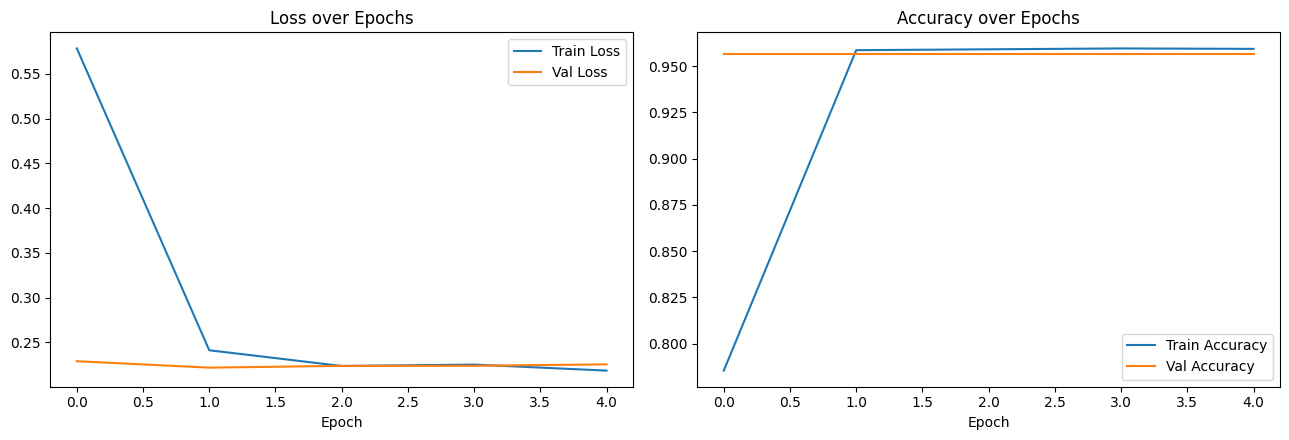

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("reports/lstm_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Evaluate on Test Set

In [8]:
test_loss, test_acc = model.evaluate(X_test_pad, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")

y_pred_probs = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
print(f"Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, zero_division=0))

Test Accuracy: 0.9643 | Test Loss: 0.1871


Precision: 0.9643 | Recall: 0.9643 | F1: 0.9643
              precision    recall  f1-score   support

    negative       0.97      0.97      0.97       516
     neutral       0.96      0.95      0.96       325
    positive       0.96      0.96      0.96       419

    accuracy                           0.96      1260
   macro avg       0.96      0.96      0.96      1260
weighted avg       0.96      0.96      0.96      1260



## 8. Confusion Matrix — Where Does the Model Fail?

A common failure mode: does the model confuse **sarcasm** with **positivity**?
Sarcastic negative tweets that use positive-sounding words ("great, another delay!")
are the hardest cases for both classical and deep learning approaches.

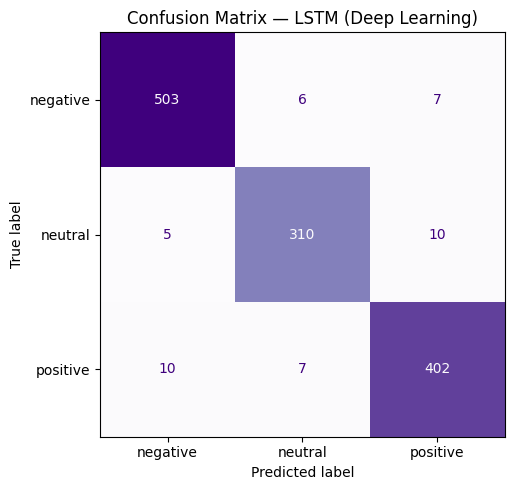

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_title("Confusion Matrix — LSTM (Deep Learning)")
plt.tight_layout()
plt.savefig("reports/confusion_matrix_lstm.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Inference — Test with Custom Inputs

In [10]:
def predict_sentiment(text):
    clean = tokenize_lemmatize(clean_tweet(text))
    seq = tokenizer.texts_to_sequences([clean])
    pad = pad_sequences(seq, maxlen=MAX_LEN, padding="post", truncating="post")
    probs = model.predict(pad, verbose=0)[0]
    label = label_encoder.inverse_transform([np.argmax(probs)])[0]
    return label, dict(zip(label_encoder.classes_, probs.round(3)))

for sample in ["The service was amazing!", "I waited 4 hours just to get a cold burger."]:
    label, probs = predict_sentiment(sample)
    print(f"'{sample}' -> {label}  {probs}")

'The service was amazing!' -> positive  {'negative': np.float32(0.12), 'neutral': np.float32(0.101), 'positive': np.float32(0.779)}
'I waited 4 hours just to get a cold burger.' -> negative  {'negative': np.float32(0.973), 'neutral': np.float32(0.016), 'positive': np.float32(0.011)}


## 10. Save Model + Tokenizer + Label Encoder (for the Streamlit Dashboard)

In [11]:
model.save("models/lstm_model.keras")

with open("models/tokenizer.json", "w") as f:
    f.write(tokenizer.to_json())

import joblib
joblib.dump(label_encoder, "models/label_encoder.joblib")

lstm_metrics = {
    "accuracy": float(test_acc),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "max_len": MAX_LEN,
    "vocab_size": VOCAB_SIZE,
}
with open("models/lstm_metrics.json", "w") as f:
    json.dump(lstm_metrics, f, indent=2)

print("Saved LSTM model, tokenizer, label encoder, and metrics.")
lstm_metrics

Saved LSTM model, tokenizer, label encoder, and metrics.


{'accuracy': 0.9642857313156128,
 'precision': 0.9642677934141888,
 'recall': 0.9642857142857143,
 'f1': 0.9642729122437554,
 'max_len': 30,
 'vocab_size': 8000}